# Machine Learning Model Comparison — Nusselt Number Prediction

This notebook applies **4 regression models** to the uploaded dataset (`data.csv`) and compares
their performance using multiple evaluation metrics, with **R² (coefficient of determination)**
as the primary ("best-fit") measure, alongside RMSE, MAE and MSE.

**Dataset columns:**
- `phi`  – nanoparticle volume fraction (feature)
- `Ha`   – Hartmann number (feature)
- `Ra`   – Rayleigh number (feature)
- `Nu`   – Nusselt number (**target**, continuous → this is a regression problem)

**Models compared:**
1. Linear Regression
2. Support Vector Regression (SVR)
3. Random Forest Regressor
4. Gradient Boosting Regressor

**Workflow:** load & explore data → preprocess/scale → train each model → evaluate with
R² / RMSE / MAE / MSE + 5-fold cross-validation → visualize & compare results.


## 1. Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    mean_absolute_percentage_error
)
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42


## 2. Load Dataset

> Update the `DATA_PATH` below if your CSV file has a different name / location.
> By default this notebook looks for `data.csv` in the same folder as the notebook.


In [3]:
DATA_PATH = "data.csv"

df = pd.read_csv(DATA_PATH)

# Drop an index-like column if present (e.g. "No.")
for col in df.columns:
    if col.strip().lower() in ("no.", "no", "index", "id"):
        df = df.drop(columns=[col])

print("Shape:", df.shape)
df.head(10)


Shape: (120, 4)


,phi,Ha,Ra,Nu
0,0.01,0,1000,6.180
1,0.01,0,10000,6.412
2,0.01,0,100000,8.348
3,0.01,0,1000000,11.716
4,0.01,20,1000,6.179
5,0.01,20,10000,6.205
6,0.01,20,100000,7.793
7,0.01,20,1000000,11.229
8,0.01,40,1000,6.179
9,0.01,40,10000,6.183


## 3. Exploratory Data Analysis (EDA)

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
phi,120.0,0.030000,0.014201,0.010,0.020,0.0300,0.04000,0.050
Ha,120.0,50.000000,34.299717,0.000,20.000,50.0000,80.00000,100.000
Ra,120.0,277750.000000,420540.093913,1000.000,7750.000,55000.0000,325000.00000,1000000.000
Nu,120.0,7.699992,1.782864,6.179,6.527,6.8745,8.59175,12.531


In [5]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nData types:")
print(df.dtypes)


Missing values per column:
phi    0
Ha     0
Ra     0
Nu     0
dtype: int64

Data types:
phi    float64
Ha       int64
Ra       int64
Nu     float64
dtype: object


In [6]:
# Define target column: change here if your target has a different name
TARGET = "Nu"
FEATURES = [c for c in df.columns if c != TARGET]
print("Features:", FEATURES)
print("Target  :", TARGET)


Features: ['phi', 'Ha', 'Ra']
Target  : Nu


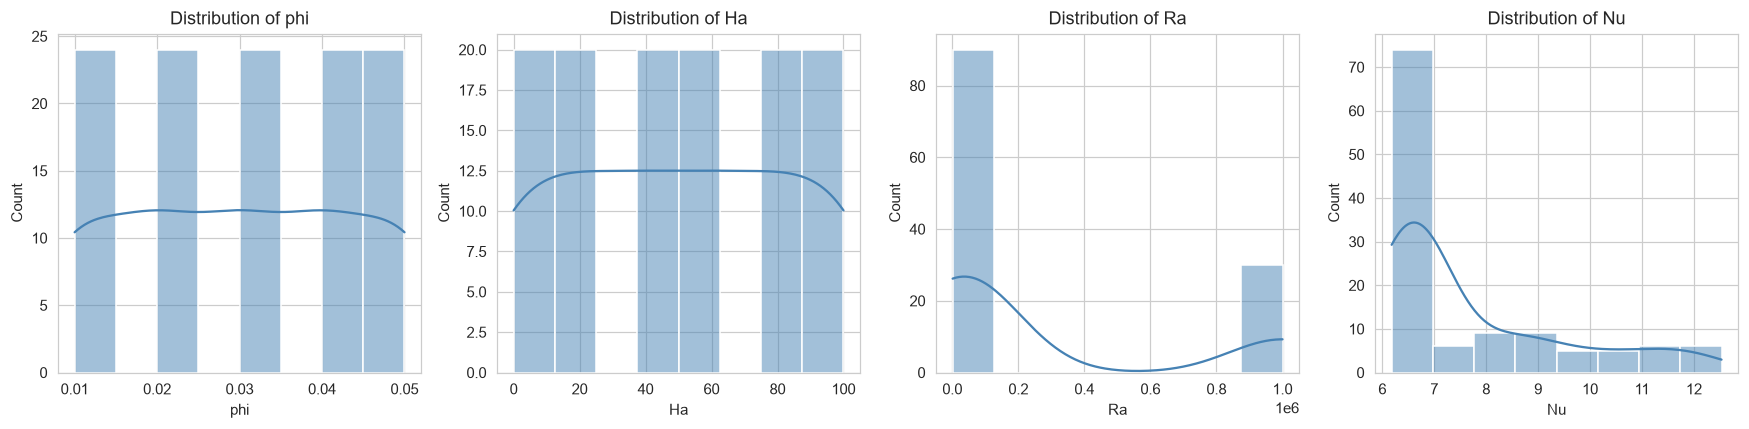

In [7]:
fig, axes = plt.subplots(1, len(FEATURES) + 1, figsize=(4*(len(FEATURES)+1), 4))
for i, col in enumerate(FEATURES + [TARGET]):
    sns.histplot(df[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()


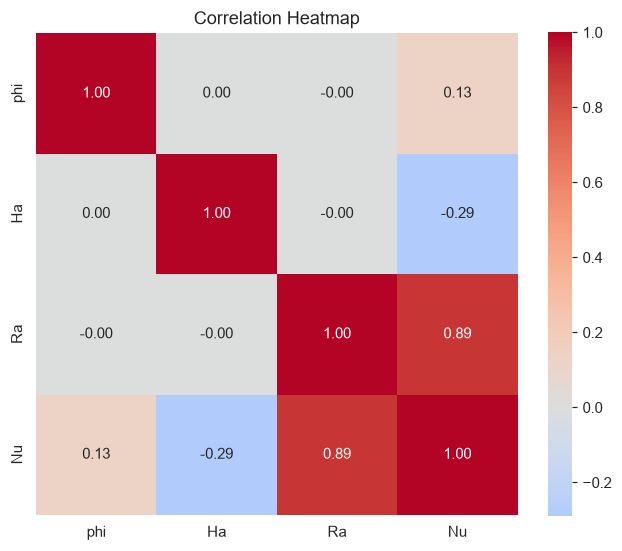

In [8]:
plt.figure(figsize=(6, 5))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


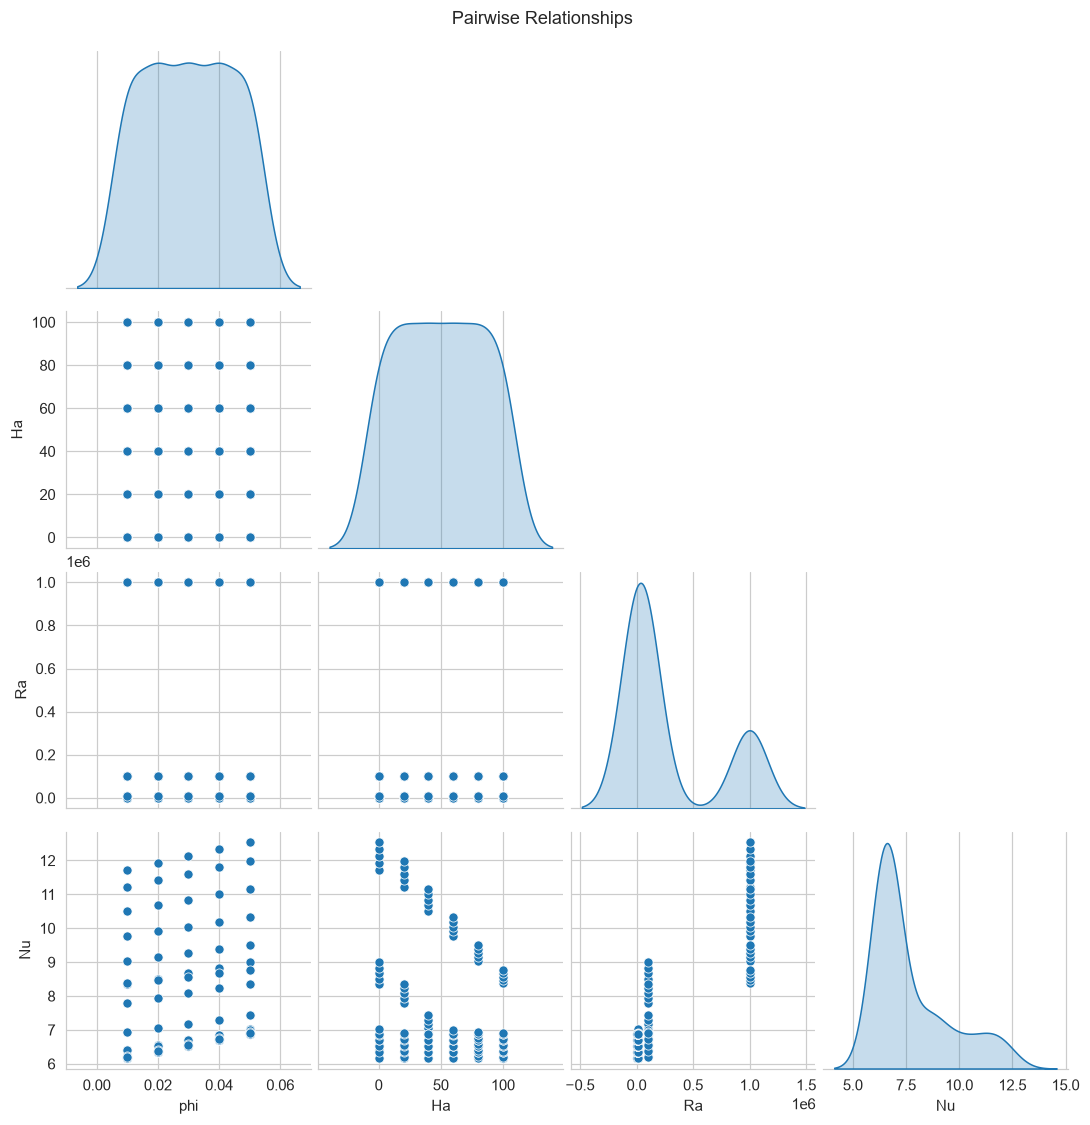

In [9]:
sns.pairplot(df, diag_kind="kde", corner=True)
plt.suptitle("Pairwise Relationships", y=1.02)
plt.show()


## 4. Preprocessing

- Split into features (X) and target (y)
- Train/test split (80/20)
- Standardize features (important for SVR, harmless for the others)


In [10]:
X = df[FEATURES].values
y = df[TARGET].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Train size:", X_train.shape, " Test size:", X_test.shape)


Train size: (96, 3)  Test size: (24, 3)


## 5. Define the 4 Models

Tree-based models (Random Forest, Gradient Boosting) are scale-invariant, but we use the scaled
features consistently across all models for a fair, uniform pipeline.


In [11]:
models = {
    "Linear Regression": LinearRegression(),
    "SVR (RBF Kernel)": SVR(kernel="rbf", C=100, gamma="scale", epsilon=0.1),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE
    ),
}


## 6. Train, Predict & Evaluate

**Primary ("perfect") measure: R² score** — the proportion of variance in the target explained
by the model (1.0 = perfect fit). We also report RMSE, MAE, MAPE, and 5-fold cross-validated R²
for a fuller picture and to check for overfitting.


In [12]:

# ============================================================
# ORIGINAL MODEL TRAINING AND EVALUATION (BEFORE TUNING)
# ============================================================

results = []
predictions = {}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Fit scaler using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Cross-validation scaler pipeline
from sklearn.pipeline import Pipeline

for name, model in models.items():

    # Train model
    model.fit(X_train_scaled, y_train)

    # Predict test data
    y_pred = model.predict(X_test_scaled)

    predictions[name] = y_pred

    # Calculate test metrics
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    # Cross-validation without data leakage
    cv_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", models[name])
    ])

    cv_scores = cross_val_score(
        cv_pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="r2"
    )

    results.append({
        "Model": name,
        "R2 (Test)": r2,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape,
        "CV R2 (mean)": cv_scores.mean(),
        "CV R2 (std)": cv_scores.std()
    })

# Create original results table
results_df = pd.DataFrame(results).sort_values(
    "R2 (Test)", ascending=False
).reset_index(drop=True)

# Save original results before tuning
original_results_df = results_df.copy()

# print("Original model results saved successfully!")

# display(original_results_df)


In [28]:

# ============================================================
# SECTION 7: HYPERPARAMETER OPTIMIZATION
# ============================================================

# 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Define hyperparameter grids
param_grids = {

    "Linear Regression": {
        "model": LinearRegression(),
        "params": {
            "model__fit_intercept": [True, False]
        }
    },

    "SVR (RBF Kernel)": {
        "model": SVR(),
        "params": {
            "model__kernel": ["rbf", "linear"],
            "model__C": [1, 10, 100, 500, 1000],
            "model__gamma": ["scale", 0.01, 0.05, 0.1],
            "model__epsilon": [0.01, 0.1, 0.2, 0.3]
        }
    },

    "Random Forest": {
        "model": RandomForestRegressor(
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__n_estimators": [100, 300, 500],
            "model__max_depth": [None, 5, 10],
            "model__min_samples_split": [2, 5],
            "model__min_samples_leaf": [1, 2]
        }
    },

    "Gradient Boosting": {
        "model": GradientBoostingRegressor(
            random_state=RANDOM_STATE
        ),
        "params": {
            "model__n_estimators": [100, 300, 500],
            "model__learning_rate": [0.01, 0.05, 0.1],
            "model__max_depth": [2, 3, 4],
            "model__min_samples_split": [2, 5],
            "model__min_samples_leaf": [1, 2]
        }
    }
}

# Store optimized models and GridSearch objects
best_models = {}
grid_searches = {}
tuning_results = []

# Perform GridSearchCV
for name, config in param_grids.items():

    print("\nOptimizing:", name)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", config["model"])
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=config["params"],
        cv=cv,
        scoring="r2",
        n_jobs=-1,
        verbose=1,
        return_train_score=True
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_
    grid_searches[name] = grid_search

    tuning_results.append({
        "Model": name,
        "Best CV R2": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

    print("Best CV R2:", grid_search.best_score_)
    print("Best Parameters:", grid_search.best_params_)

# Display tuning results
tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)



Optimizing: Linear Regression
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best CV R2: 0.874741229170243
Best Parameters: {'model__fit_intercept': True}

Optimizing: SVR (RBF Kernel)
Fitting 5 folds for each of 160 candidates, totalling 800 fits
Best CV R2: 0.9979228757258992
Best Parameters: {'model__C': 500, 'model__epsilon': 0.01, 'model__gamma': 'scale', 'model__kernel': 'rbf'}

Optimizing: Random Forest
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best CV R2: 0.9947011899050278
Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 100}

Optimizing: Gradient Boosting
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best CV R2: 0.9985707873854812
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 500}


,Model,Best CV R2,Best Parameters
0,Linear Regression,0.874741,{'model__fit_intercept': True}
1,SVR (RBF Kernel),0.997923,"{'model__C': 500, 'model__epsilon': 0.01, 'mod..."
2,Random Forest,0.994701,"{'model__max_depth': None, 'model__min_samples..."
3,Gradient Boosting,0.998571,"{'model__learning_rate': 0.1, 'model__max_dept..."


In [29]:

# ============================================================
# EVALUATION OF OPTIMIZED MODELS
# ============================================================

tuned_results = []
predictions = {}

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(
        y_test, y_pred
    ) * 100

    cv_score = grid_searches[name].best_score_

    tuned_results.append({
        "Model": name,
        "R2 (Test)": r2,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape,
        "CV R2 (mean)": cv_score
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df = tuned_results_df.sort_values(
    "R2 (Test)", ascending=False
).reset_index(drop=True)

display(tuned_results_df)


,Model,R2 (Test),RMSE,MAE,MAPE (%),CV R2 (mean)
0,SVR (RBF Kernel),0.999577,0.036737,0.026975,0.379708,0.997923
1,Gradient Boosting,0.999525,0.038928,0.028405,0.380430,0.998571
2,Random Forest,0.997142,0.095508,0.064020,0.794303,0.994701
3,Linear Regression,0.910392,0.534757,0.450354,5.985472,0.874741


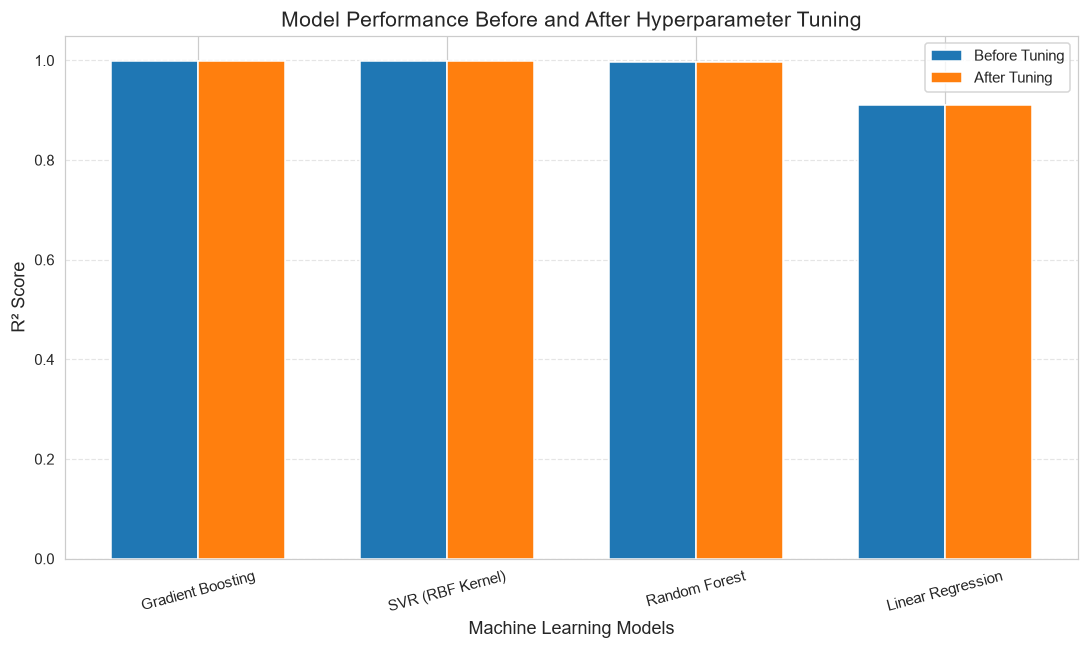

In [30]:

# ============================================================
# GRAPH 1: BEFORE VS AFTER HYPERPARAMETER TUNING
# ============================================================

comparison = original_results_df[
    ["Model", "R2 (Test)"]
].merge(
    tuned_results_df[["Model", "R2 (Test)"]],
    on="Model",
    suffixes=("_Before", "_After")
)

x = np.arange(len(comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width/2,
    comparison["R2 (Test)_Before"],
    width,
    label="Before Tuning"
)

ax.bar(
    x + width/2,
    comparison["R2 (Test)_After"],
    width,
    label="After Tuning"
)

ax.set_xlabel("Machine Learning Models", fontsize=12)
ax.set_ylabel("R² Score", fontsize=12)

ax.set_title(
    "Model Performance Before and After Hyperparameter Tuning",
    fontsize=14
)

ax.set_xticks(x)
ax.set_xticklabels(comparison["Model"], rotation=15)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [31]:

from scipy.interpolate import make_interp_spline

def smooth_plot(ax, x, y, label=None, color=None):
    """
    Plot original data points with a smooth interpolated curve.
    """

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Sort x values
    order = np.argsort(x)
    x = x[order]
    y = y[order]

    # Smooth curve
    if len(x) >= 3:
        x_smooth = np.linspace(x.min(), x.max(), 300)

        spline = make_interp_spline(
            x, y, k=min(3, len(x)-1)
        )

        y_smooth = spline(x_smooth)

        ax.plot(
            x_smooth,
            y_smooth,
            linewidth=2.5,
            label=label,
            color=color
        )

    else:
        ax.plot(
            x, y,
            linewidth=2.5,
            label=label,
            color=color
        )

    # Show actual calculated points
    ax.scatter(
        x, y,
        s=55,
        edgecolors="black",
        linewidths=0.6,
        zorder=5,
        color=color
    )


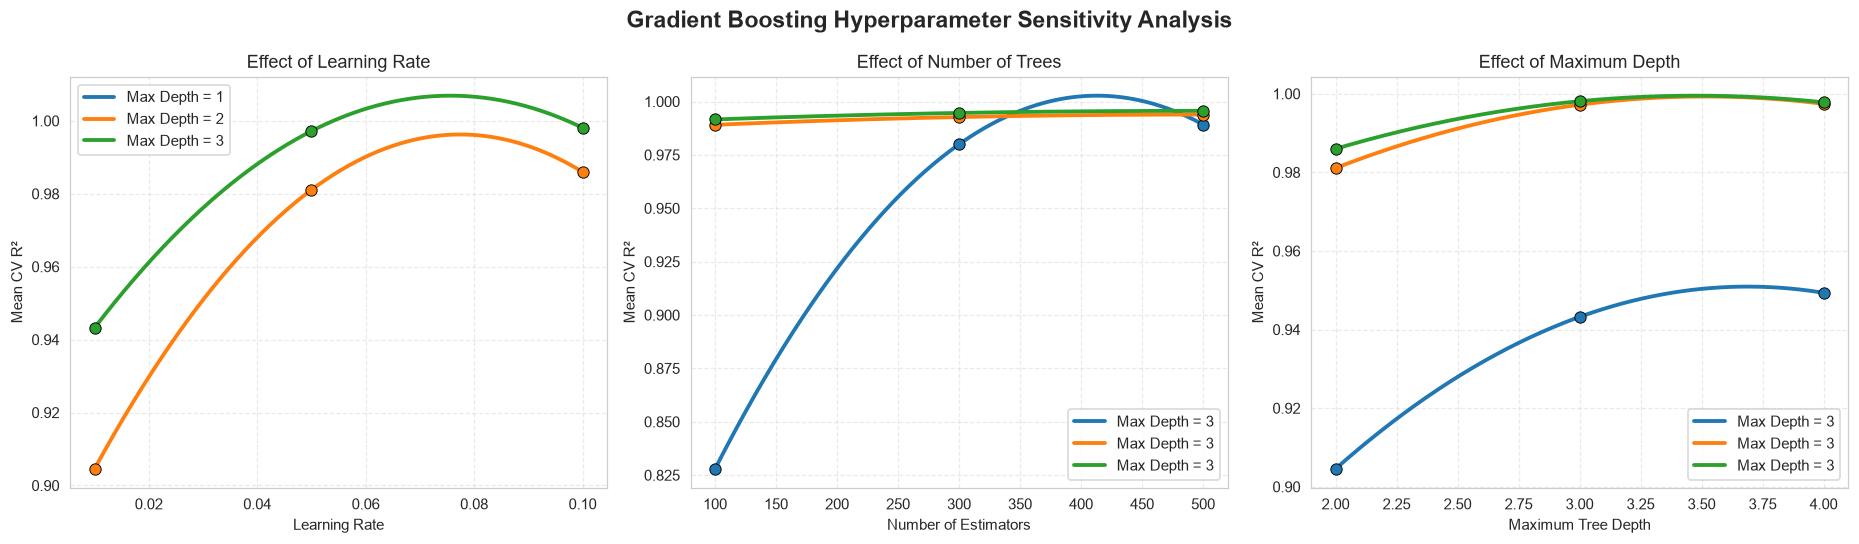

In [34]:

# ============================================================
# GRADIENT BOOSTING: HYPERPARAMETER SENSITIVITY
# ============================================================

gb_results = pd.DataFrame(
    grid_searches["Gradient Boosting"].cv_results_
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Effect of learning rate
for depth in [1, 2, 3]:

    subset = gb_results[
        gb_results["param_model__max_depth"] == depth
    ]

    grouped = subset.groupby(
        "param_model__learning_rate"
    )["mean_test_score"].mean()

    smooth_plot(
    axes[0],
    grouped.index.astype(float),
    grouped.values,
    label=f"Max Depth = {depth}"
)
axes[0].set_xlabel("Learning Rate")
axes[0].set_ylabel("Mean CV R²")
axes[0].set_title("Effect of Learning Rate")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# 2. Effect of number of estimators
for lr in [0.01, 0.05, 0.1]:

    subset = gb_results[
        gb_results["param_model__learning_rate"] == lr
    ]

    grouped = subset.groupby(
        "param_model__n_estimators"
    )["mean_test_score"].mean()

    smooth_plot(
    axes[1],
    grouped.index.astype(float),
    grouped.values,
    label=f"Max Depth = {depth}"
)
axes[1].set_xlabel("Number of Estimators")
axes[1].set_ylabel("Mean CV R²")
axes[1].set_title("Effect of Number of Trees")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

# 3. Effect of maximum depth
for lr in [0.01, 0.05, 0.1]:

    subset = gb_results[
        gb_results["param_model__learning_rate"] == lr
    ]

    grouped = subset.groupby(
        "param_model__max_depth"
    )["mean_test_score"].mean()

    smooth_plot(
    axes[2],
    grouped.index.astype(float),
    grouped.values,
    label=f"Max Depth = {depth}"
)

axes[2].set_xlabel("Maximum Tree Depth")
axes[2].set_ylabel("Mean CV R²")
axes[2].set_title("Effect of Maximum Depth")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.4)

fig.suptitle(
    "Gradient Boosting Hyperparameter Sensitivity Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


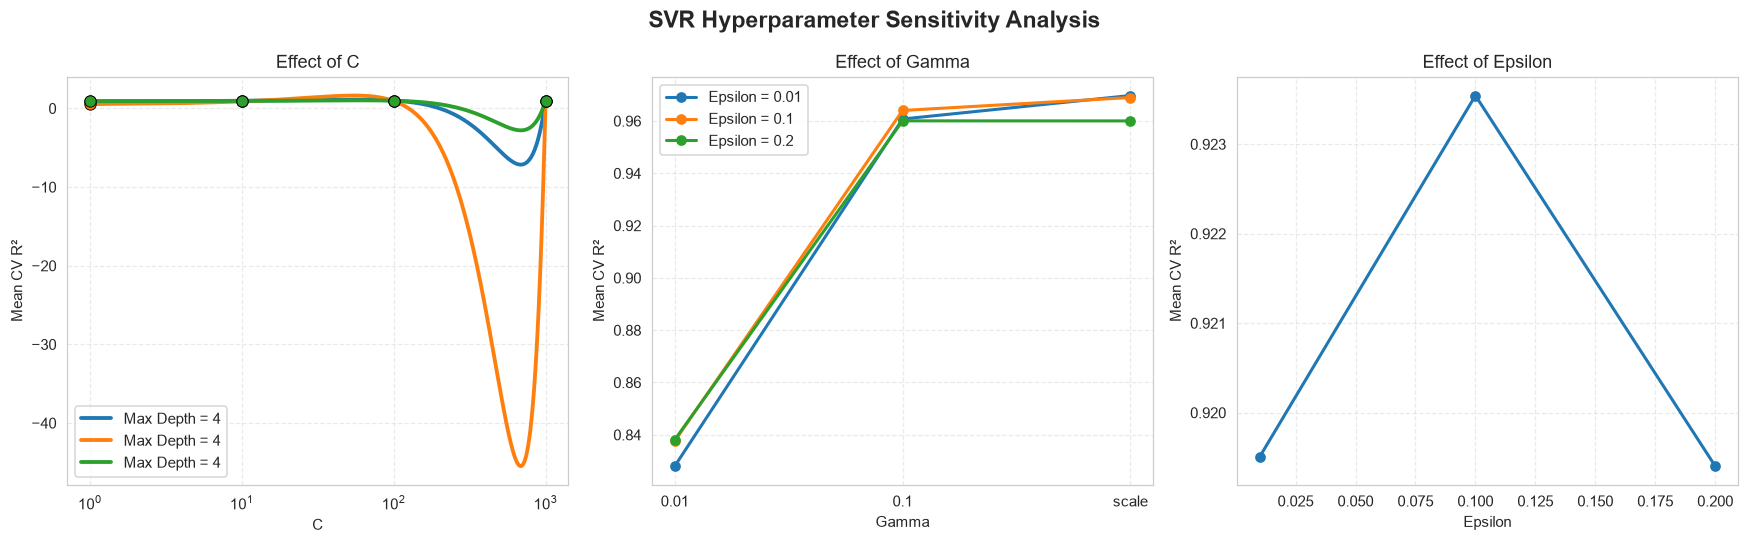

In [17]:

# ============================================================
# SVR: HYPERPARAMETER SENSITIVITY LINE GRAPHS
# ============================================================

svr_results = pd.DataFrame(
    grid_searches["SVR (RBF Kernel)"].cv_results_
)

# Use RBF kernel for this analysis
svr_results = svr_results[
    svr_results["param_model__kernel"] == "rbf"
].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Effect of C
for gamma in ["scale", 0.01, 0.1]:

    subset = svr_results[
        svr_results["param_model__gamma"] == gamma
    ]

    grouped = subset.groupby(
        "param_model__C"
    )["mean_test_score"].mean()

    smooth_plot(
    axes[0],
    grouped.index.astype(float),
    grouped.values,
    label=f"Max Depth = {depth}"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("C")
axes[0].set_ylabel("Mean CV R²")
axes[0].set_title("Effect of C")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# 2. Effect of Gamma
for epsilon in [0.01, 0.1, 0.2]:

    subset = svr_results[
        svr_results["param_model__epsilon"] == epsilon
    ]

    grouped = subset.groupby(
        "param_model__gamma"
    )["mean_test_score"].mean()

    axes[1].plot(
        grouped.index.astype(str),
        grouped.values,
        marker="o",
        linewidth=2,
        label=f"Epsilon = {epsilon}"
    )

axes[1].set_xlabel("Gamma")
axes[1].set_ylabel("Mean CV R²")
axes[1].set_title("Effect of Gamma")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

# 3. Effect of Epsilon
grouped = svr_results.groupby(
    "param_model__epsilon"
)["mean_test_score"].mean()

axes[2].plot(
    grouped.index.astype(float),
    grouped.values,
    marker="o",
    linewidth=2
)

axes[2].set_xlabel("Epsilon")
axes[2].set_ylabel("Mean CV R²")
axes[2].set_title("Effect of Epsilon")
axes[2].grid(True, linestyle="--", alpha=0.4)

fig.suptitle(
    "SVR Hyperparameter Sensitivity Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


## 7. Model Comparison — Metric Table (styled)

In [35]:
results_df.style.format({
    "R2 (Test)": "{:.4f}",
    "RMSE": "{:.4f}",
    "MAE": "{:.4f}",
    "MAPE (%)": "{:.2f}",
    "CV R2 (mean)": "{:.4f}",
    "CV R2 (std)": "{:.4f}",
}).background_gradient(subset=["R2 (Test)", "CV R2 (mean)"], cmap="Greens")  .background_gradient(subset=["RMSE", "MAE", "MAPE (%)"], cmap="Reds_r")


AttributeError: The '.style' accessor requires jinja2

## 8. Comparison Bar Charts

C:\Users\ashik\AppData\Local\Temp\ipykernel_1180\1909951077.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=order, x="Model", y="R2 (Test)", ax=axes[0], palette="viridis")
C:\Users\ashik\AppData\Local\Temp\ipykernel_1180\1909951077.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=order2, x="Model", y="RMSE", ax=axes[1], palette="magma")


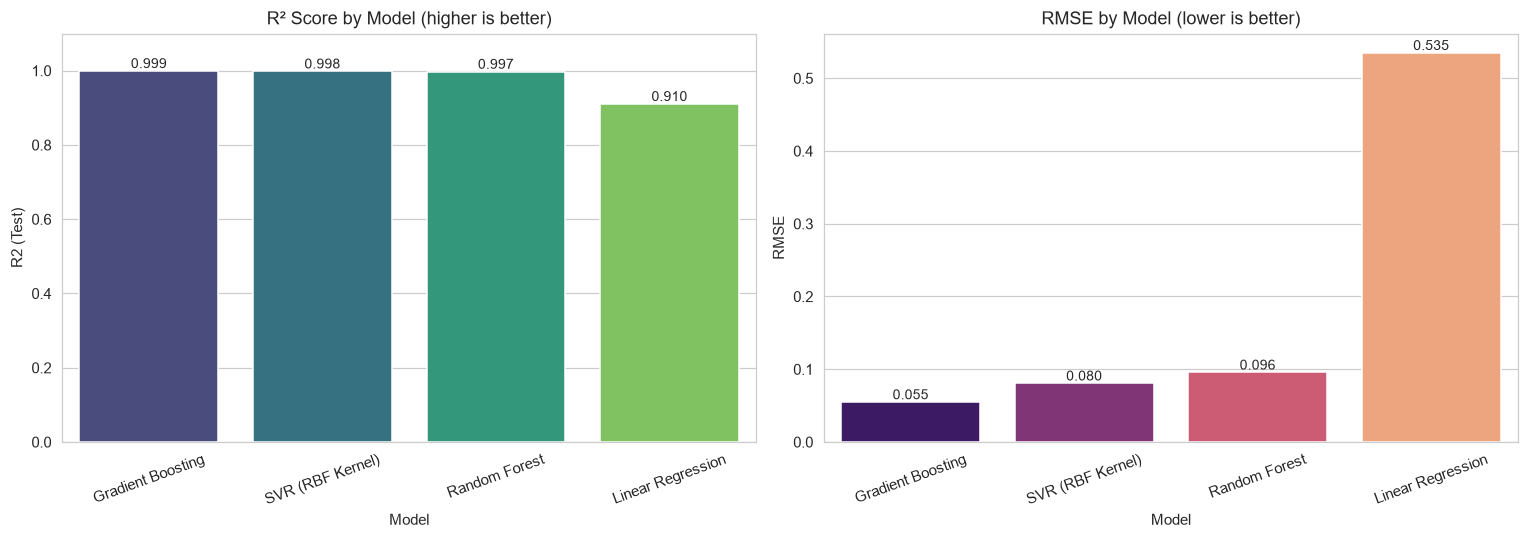

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

order = results_df.sort_values("R2 (Test)", ascending=False)
sns.barplot(data=order, x="Model", y="R2 (Test)", ax=axes[0], palette="viridis")
axes[0].set_title("R² Score by Model (higher is better)")
axes[0].set_ylim(0, 1.1)
axes[0].tick_params(axis='x', rotation=20)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width()/2, p.get_height()),
                      ha="center", va="bottom", fontsize=9)

order2 = results_df.sort_values("RMSE", ascending=True)
sns.barplot(data=order2, x="Model", y="RMSE", ax=axes[1], palette="magma")
axes[1].set_title("RMSE by Model (lower is better)")
axes[1].tick_params(axis='x', rotation=20)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width()/2, p.get_height()),
                      ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()


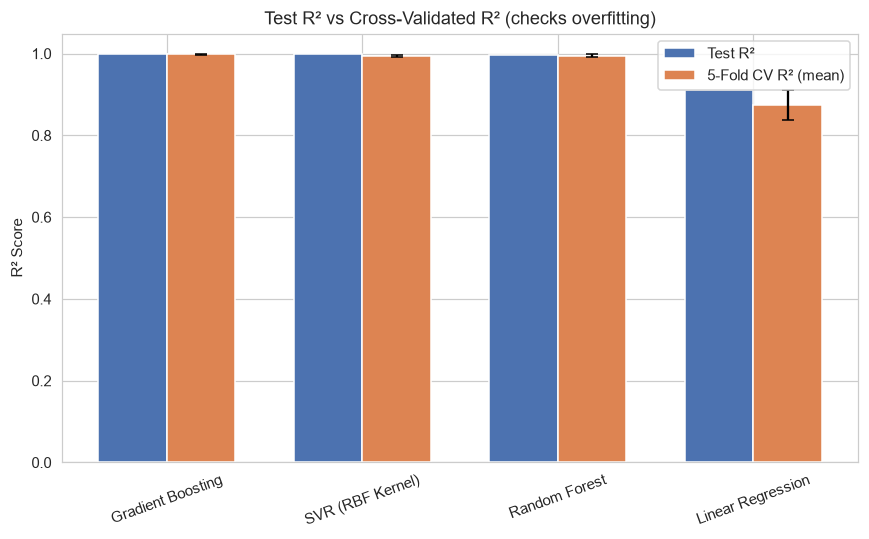

In [37]:
plt.figure(figsize=(8, 5))
x = np.arange(len(results_df))
width = 0.35
plt.bar(x - width/2, results_df["R2 (Test)"], width, label="Test R²", color="#4C72B0")
plt.bar(x + width/2, results_df["CV R2 (mean)"], width, label="5-Fold CV R² (mean)", color="#DD8452")
plt.errorbar(x + width/2, results_df["CV R2 (mean)"], yerr=results_df["CV R2 (std)"],
             fmt="none", ecolor="black", capsize=4)
plt.xticks(x, results_df["Model"], rotation=20)
plt.ylabel("R² Score")
plt.title("Test R² vs Cross-Validated R² (checks overfitting)")
plt.legend()
plt.tight_layout()
plt.show()


## 9. Actual vs Predicted Plots (per model)

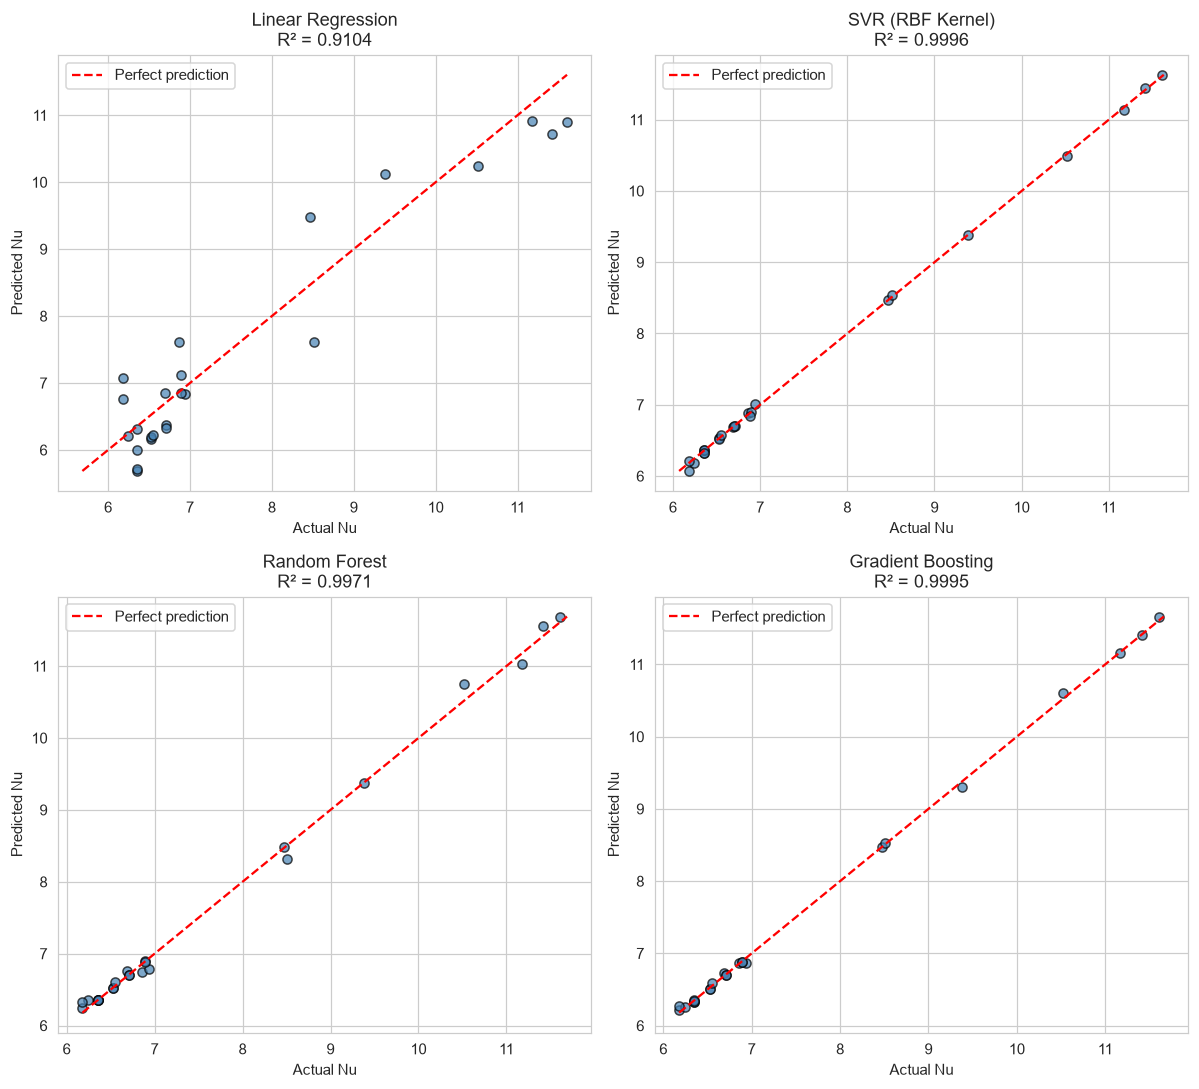

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.7, edgecolor="k", color="steelblue")
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    r2 = r2_score(y_test, y_pred)
    ax.set_title(f"{name}\nR² = {r2:.4f}")
    ax.set_xlabel("Actual Nu")
    ax.set_ylabel("Predicted Nu")
    ax.legend()

plt.tight_layout()
plt.show()


## 10. Residual Plots (per model)

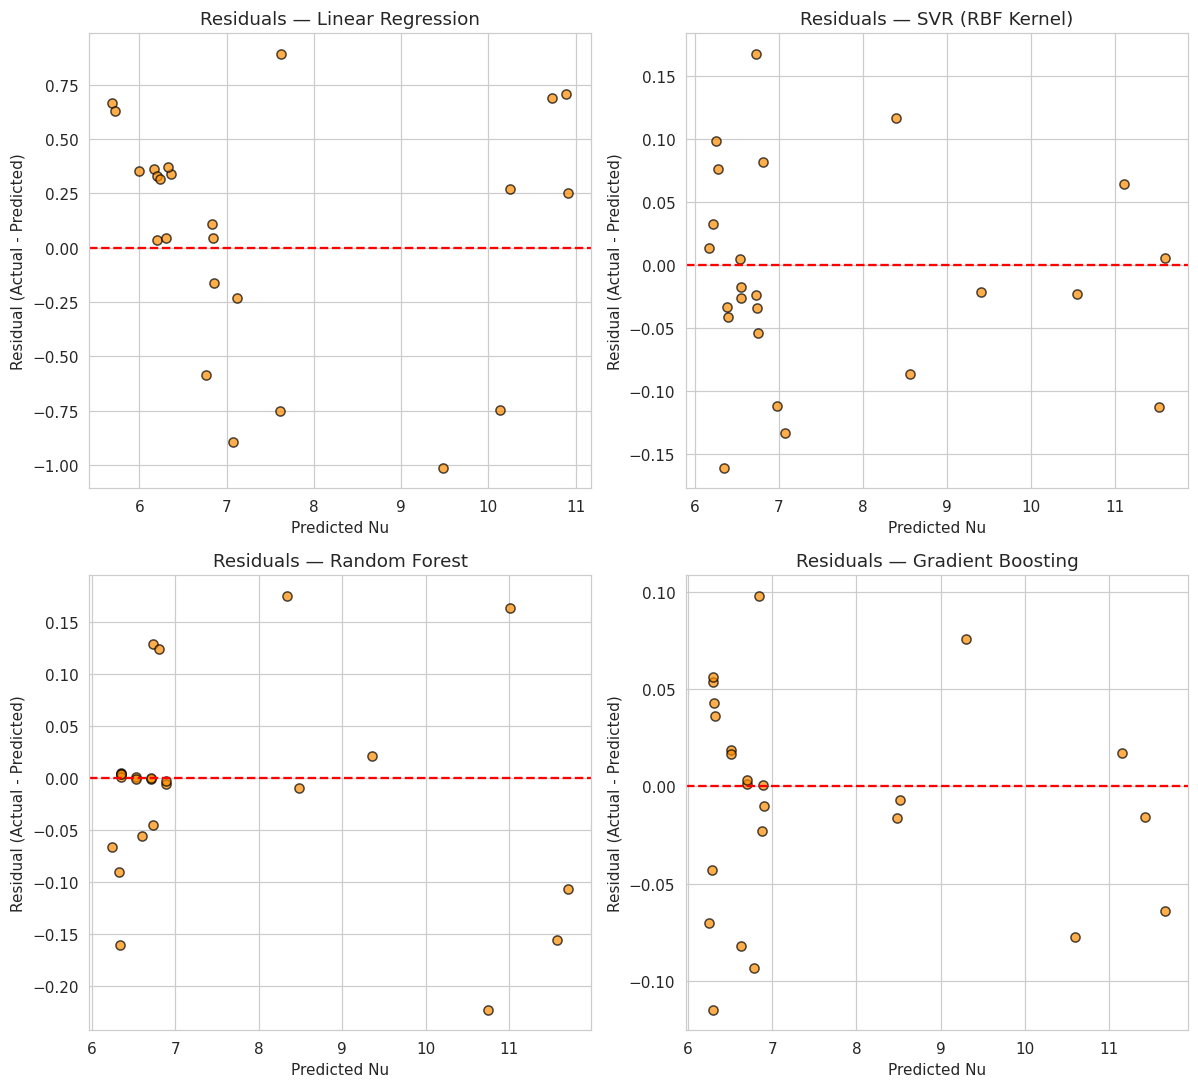

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes = axes.ravel()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    residuals = y_test - y_pred
    ax.scatter(y_pred, residuals, alpha=0.7, edgecolor="k", color="darkorange")
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"Residuals — {name}")
    ax.set_xlabel("Predicted Nu")
    ax.set_ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()


## 11. Feature Importance (tree-based models)

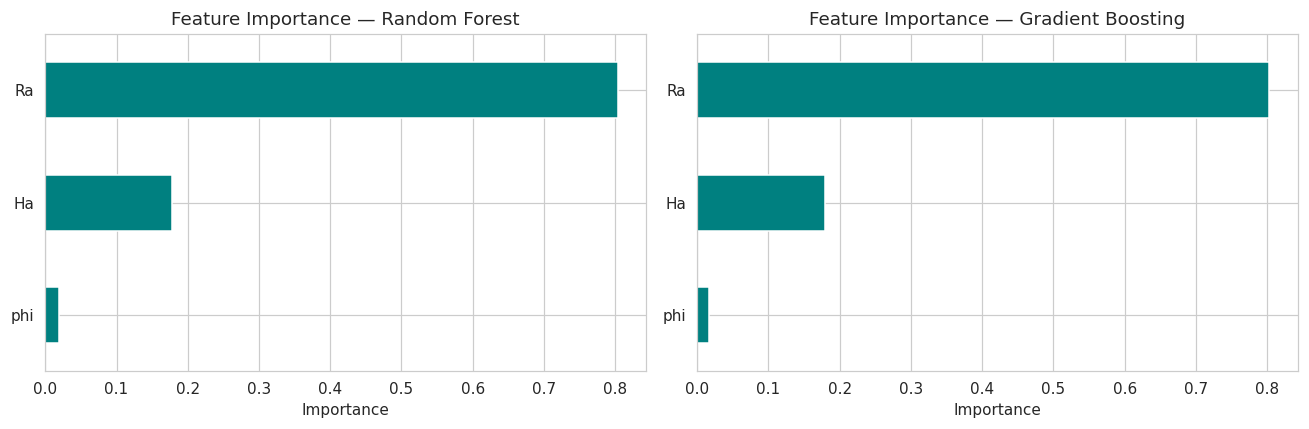

In [17]:
tree_models = {k: v for k, v in models.items() if hasattr(v, "feature_importances_")}

if tree_models:
    fig, axes = plt.subplots(1, len(tree_models), figsize=(6*len(tree_models), 4))
    if len(tree_models) == 1:
        axes = [axes]
    for ax, (name, model) in zip(axes, tree_models.items()):
        importances = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
        importances.plot(kind="barh", ax=ax, color="teal")
        ax.set_title(f"Feature Importance — {name}")
        ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print("No tree-based models with feature_importances_ in this comparison.")


## 12. Summary & Best Model

The table below ranks all 4 models by **R² (Test)**, our primary performance measure, and shows
the best-performing model along with its full metric breakdown.


In [18]:
best_row = results_df.iloc[0]
print("=" * 55)
print(f"BEST MODEL: {best_row['Model']}")
print("=" * 55)
print(f"  R2 (Test)      : {best_row['R2 (Test)']:.4f}")
print(f"  RMSE           : {best_row['RMSE']:.4f}")
print(f"  MAE            : {best_row['MAE']:.4f}")
print(f"  MAPE (%)       : {best_row['MAPE (%)']:.2f}")
print(f"  CV R2 (mean)   : {best_row['CV R2 (mean)']:.4f}  (+/- {best_row['CV R2 (std)']:.4f})")
print("=" * 55)

results_df


BEST MODEL: Gradient Boosting
  R2 (Test)      : 0.9991
  RMSE           : 0.0547
  MAE            : 0.0431
  MAPE (%)       : 0.60
  CV R2 (mean)   : 0.9983  (+/- 0.0016)


,Model,R2 (Test),RMSE,MAE,MAPE (%),CV R2 (mean),CV R2 (std)
0,Gradient Boosting,0.999062,0.054720,0.043131,0.601905,0.998256,0.001627
1,SVR (RBF Kernel),0.997969,0.080499,0.064312,0.888993,0.994489,0.004762
2,Random Forest,0.997139,0.095555,0.064661,0.790298,0.993665,0.004205
3,Linear Regression,0.910392,0.534757,0.450354,5.985472,0.836070,0.127034
